# 11 · Modelo definitivo H8

H8 es el modelo final del proyecto. Es la receta de H6 con tres cambios, los dos primeros pedidos en
la asesoría del profesor:

| Cambio | Opción | Qué hace |
|---|---|---|
| Sin EMA | `--ema 0` | Se guardan los pesos del entrenamiento, no un promedio móvil |
| Giro del aumento en milímetros | `--aug-mm` | El giro se aplica en el espacio físico (espaciado de la cabecera) y no en la grilla de píxeles estirada, que deformaba la pelvis |
| Aumento de ruido gaussiano | `--aug-noise 0.1` | En el 30 % de las muestras se suma ruido con desviación al azar de hasta 0.1 (escala 0-1) |

La arquitectura no cambia: backbone propio de 32 canales con CBAM de una etapa y tres cabezas
(clasificación, detección con grid y NMS propios, segmentación semántica e instancia). 2.74 M de
parámetros.

**Este notebook no entrena ni evalúa nada:** lee los resultados guardados en `outputs/h8/`. El
entrenamiento se hizo en Kaggle (GPU T4, 67 minutos) y las evaluaciones, sobre el volumen completo
de cada caso con TTA de espejo. Los comandos están en `docs/modelo_h8.md`.

> Uso exclusivamente académico. No es un dispositivo médico ni debe usarse para decisiones clínicas.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
H8 = ROOT / "outputs" / "h8"
FIG = H8 / "figuras"
FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)


def leer(ruta):
    return json.loads((ROOT / ruta).read_text())


def todo(ruta):
    return leer(ruta)["subsets"]["todo"]


OBJETIVOS = {"classification_f1_macro": ("F1 de clasificación", 0.85),
             "classification_auc_macro": ("AUC de clasificación", 0.85),
             "detection_iou_mean": ("IoU de detección", 0.65),
             "detection_map50": ("mAP50", 0.65),
             "detection_map50_95": ("mAP50:95", 0.40),
             "segmentation_dice_macro": ("Dice de segmentación", 0.85),
             "segmentation_iou_macro": ("IoU de segmentación", 0.70),
             "instance_dice_matched": ("Dice por fragmento", 0.85),
             "instance_iou_matched": ("IoU por fragmento", 0.70)}
print("Resultados en", H8.relative_to(ROOT))

Resultados en outputs\h8


## 1. Entrenamiento

Receta: 60 épocas de 2 500 cortes, lote 16, tasa de aprendizaje 0.002 con coseno, peso ×3 a los
fragmentos secundarios, orientación canónica según la cabecera, aumento geométrico con rotación de
±35° en milímetros, aumento de ruido y semilla 42. La curva usa la validación rápida del
entrenamiento (un corte de cada seis), no la evaluación final.

{'epochs': 60, 'lr': 0.002, 'batch_size': 16, 'base_channels': 32, 'cbam': '1', 'ema': 0.0, 'aug_mm': True, 'aug_noise': 0.1, 'aug_rot_deg': 35.0, 'canonical': True, 'seed': 42}
Minutos: 66.7 | cortado por tiempo: False


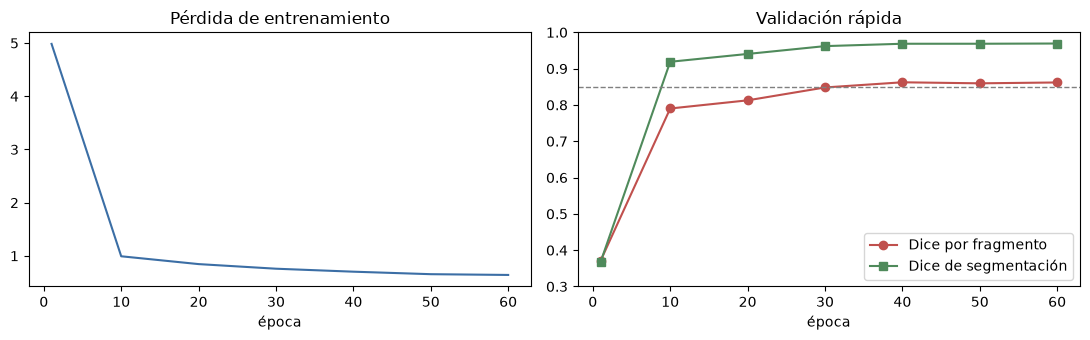

In [2]:
historial = leer("outputs/h8/h8_aumm_noise01_noema_w32_e60_s42.json")
args = historial["args"]
print({k: args[k] for k in ("epochs", "lr", "batch_size", "base_channels", "cbam", "ema", "aug_mm",
                            "aug_noise", "aug_rot_deg", "canonical", "seed")})
print(f"Minutos: {historial['minutes']:.1f} | cortado por tiempo: {historial['stopped_early']}")

puntos = [h for h in historial["history"] if "instance_dice_matched" in h]
epocas = [h["epoch"] for h in historial["history"]]
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].plot(epocas, [h["loss"] for h in historial["history"]], color="#3b6ea5")
ejes[0].set(title="Pérdida de entrenamiento", xlabel="época")
ejes[1].plot([h["epoch"] for h in puntos], [h["instance_dice_matched"] for h in puntos], "o-", color="#c0504d",
             label="Dice por fragmento")
ejes[1].plot([h["epoch"] for h in puntos], [h["segmentation_dice_macro"] for h in puntos], "s-", color="#4f8a5b",
             label="Dice de segmentación")
ejes[1].axhline(0.85, ls="--", color="gray", lw=1)
ejes[1].set(title="Validación rápida", xlabel="época", ylim=(0.3, 1.0))
ejes[1].legend()
fig.tight_layout(); fig.savefig(FIG / "curva_entrenamiento.png", dpi=120); plt.show()

## 2. Las nueve métricas del curso: validación y test

Test se evaluó **una sola vez**, con la configuración escrita antes de correr
(`outputs/h8/test/CONFIG_CONGELADA_TEST_H8.md`): un modelo con TTA de espejo, tamaño 384, sin
enderezado ni suavizado.

In [3]:
val = todo("outputs/h8/validacion/val_h8_base.json")
test = todo("outputs/h8/test/test_h8.json")
tabla = pd.DataFrame([{"Métrica": nombre, "Objetivo": objetivo, "Validación": val[k], "Test": test[k],
                       "Cumple en validación": "sí" if val[k] >= objetivo else "no",
                       "Cumple en test": "sí" if test[k] >= objetivo else "no"}
                      for k, (nombre, objetivo) in OBJETIVOS.items()])
print(f"Validación: {val['n_cases']} casos, {val['n_slices']} cortes | Test: {test['n_cases']} casos, {test['n_slices']} cortes")
tabla

Validación: 15 casos, 5047 cortes | Test: 15 casos, 4664 cortes


,Métrica,Objetivo,Validación,Test,Cumple en validación,Cumple en test
0,F1 de clasificación,0.85,0.991,0.989,sí,sí
1,AUC de clasificación,0.85,0.999,0.999,sí,sí
2,IoU de detección,0.65,0.946,0.938,sí,sí
3,mAP50,0.65,0.969,0.953,sí,sí
4,mAP50:95,0.40,0.900,0.898,sí,sí
5,Dice de segmentación,0.85,0.970,0.968,sí,sí
6,IoU de segmentación,0.70,0.943,0.939,sí,sí
7,Dice por fragmento,0.85,0.865,0.874,sí,sí
8,IoU por fragmento,0.70,0.800,0.812,sí,sí


In [4]:
desglose = pd.DataFrame({
    "Validación": [val["instance_dice_primary"], val["instance_dice_secondary"], val["instance_missed_secondary"],
                   leer("outputs/h8/validacion/val_h8_base.json")["subsets"]["centro_15_85"]["instance_dice_matched"],
                   leer("outputs/h8/validacion/val_h8_base.json")["subsets"]["extremos"]["instance_dice_matched"],
                   val["segmentation_dice_sacro"], val["segmentation_dice_coxal_izquierdo"],
                   val["segmentation_dice_coxal_derecho"], val["detection_raw_map50"], val["detection_raw_map50_95"]],
    "Test": [test["instance_dice_primary"], test["instance_dice_secondary"], test["instance_missed_secondary"],
             leer("outputs/h8/test/test_h8.json")["subsets"]["centro_15_85"]["instance_dice_matched"],
             leer("outputs/h8/test/test_h8.json")["subsets"]["extremos"]["instance_dice_matched"],
             test["segmentation_dice_sacro"], test["segmentation_dice_coxal_izquierdo"],
             test["segmentation_dice_coxal_derecho"], test["detection_raw_map50"], test["detection_raw_map50_95"]]},
    index=["Dice del fragmento principal", "Dice de los secundarios", "Secundarios sin pareja",
           "Dice por fragmento, centro del volumen", "Dice por fragmento, extremos",
           "Dice semántico, sacro", "Dice semántico, coxal izquierdo", "Dice semántico, coxal derecho",
           "mAP50 de la cabeza grid sola", "mAP50:95 de la cabeza grid sola"])
desglose

,Validación,Test
Dice del fragmento principal,0.897,0.910
Dice de los secundarios,0.769,0.760
Secundarios sin pareja,0.063,0.072
"Dice por fragmento, centro del volumen",0.874,0.885
"Dice por fragmento, extremos",0.834,0.836
"Dice semántico, sacro",0.956,0.955
"Dice semántico, coxal izquierdo",0.978,0.975
"Dice semántico, coxal derecho",0.978,0.974
mAP50 de la cabeza grid sola,0.903,0.909
mAP50:95 de la cabeza grid sola,0.534,0.566


El mAP de la tabla principal se mide sobre cajas refinadas con la máscara semántica; las dos últimas
filas son la cabeza de detección sin ese refinamiento.

### Por caso

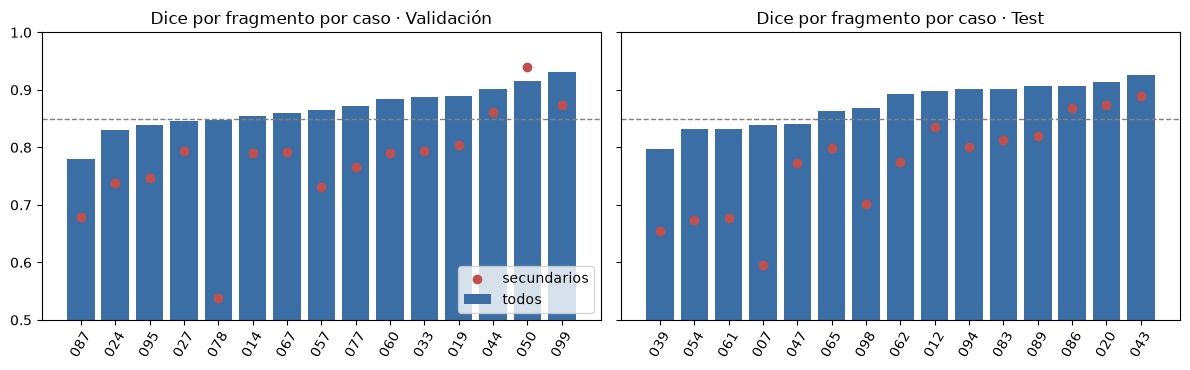

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for eje, (titulo, ruta) in zip(ejes, (("Validación", "outputs/h8/validacion/val_h8_base.json"),
                                       ("Test", "outputs/h8/test/test_h8.json"))):
    casos = sorted(leer(ruta)["per_case"], key=lambda c: c["instance_dice_matched"])
    eje.bar([c["case_id"] for c in casos], [c["instance_dice_matched"] for c in casos], color="#3b6ea5",
            label="todos")
    eje.scatter([c["case_id"] for c in casos], [c["instance_dice_secondary"] for c in casos], color="#c0504d",
                zorder=3, label="secundarios")
    eje.axhline(0.85, ls="--", color="gray", lw=1)
    eje.set(title=f"Dice por fragmento por caso · {titulo}", ylim=(0.5, 1.0))
    eje.tick_params(axis="x", rotation=60)
ejes[0].legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "dice_por_caso.png", dpi=120); plt.show()

## 3. Por qué H8: comparación con los otros cuatro modelos

Los cinco modelos comparten toda la receta salvo EMA, tipo de giro y ruido. Todos con semilla 42 y
evaluados sobre la misma validación, con cinco pruebas: sin daño, ruido gaussiano de desviación 10 y
25 (sobre 255), giro de 60° y giro de 60° con enderezado previo.

In [6]:
comparacion = pd.read_csv(ROOT / "outputs/h8/comparacion/tabla_comparativa.csv")
orden = ["H6", "H6 sin EMA", "H7", "H7 con EMA", "H8"]
pruebas = ["base", "noise10", "noise25", "rotmm60", "rotmm60_norm"]
nombres = {"base": "Sin daño", "noise10": "Ruido 10", "noise25": "Ruido 25", "rotmm60": "Giro 60°",
           "rotmm60_norm": "Giro 60° + enderezado"}
pivote = (comparacion.pivot(index="modelo", columns="prueba", values="instance_dice_matched")
          .loc[orden, pruebas].rename(columns=nombres))
pivote.insert(0, "EMA", ["sí", "no", "no", "sí", "no"])
pivote.insert(1, "Giro del aumento", ["píxeles", "píxeles", "mm", "mm", "mm"])
pivote.insert(2, "Ruido al entrenar", ["no", "no", "no", "no", "sí"])
print("Dice por fragmento en validación")
pivote

Dice por fragmento en validación


prueba,EMA,Giro del aumento,Ruido al entrenar,Sin daño,Ruido 10,Ruido 25,Giro 60°,Giro 60° + enderezado
modelo,,,,,,,,
H6,sí,píxeles,no,0.869,0.690,0.135,0.608,0.851
H6 sin EMA,no,píxeles,no,0.872,0.649,0.090,0.570,0.855
H7,no,mm,no,0.873,0.654,0.228,0.636,0.855
H7 con EMA,sí,mm,no,0.871,0.720,0.208,0.635,0.853
H8,no,mm,sí,0.865,0.860,0.835,0.612,0.849


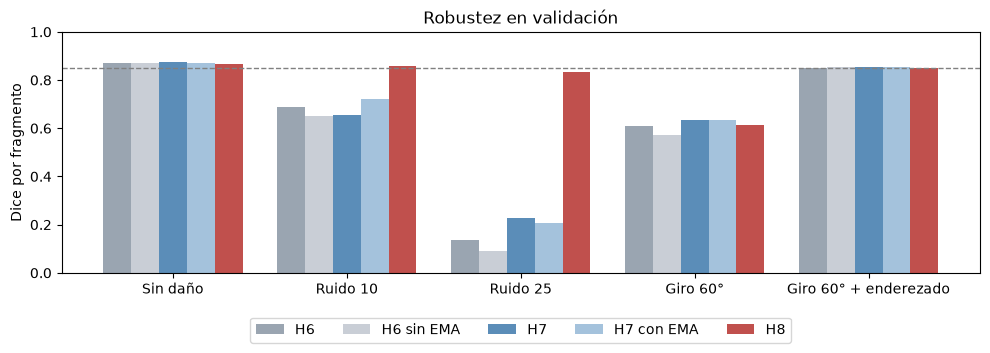

In [7]:
fig, eje = plt.subplots(figsize=(10, 3.8))
ancho = 0.16
colores = ["#9aa5b1", "#c9ced6", "#5b8db8", "#a4c2dc", "#c0504d"]
for i, modelo in enumerate(orden):
    valores = pivote.loc[modelo, list(nombres.values())].astype(float).values
    eje.bar(np.arange(5) + (i - 2) * ancho, valores, ancho, label=modelo, color=colores[i])
eje.axhline(0.85, ls="--", color="gray", lw=1)
eje.set_xticks(np.arange(5)); eje.set_xticklabels(list(nombres.values()))
eje.set(ylabel="Dice por fragmento", title="Robustez en validación", ylim=(0, 1))
eje.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.32))
fig.tight_layout(); fig.savefig(FIG / "robustez_cinco_modelos.png", dpi=120); plt.show()

**Lectura.**

- **EMA.** Quitarlo no cuesta nada en imágenes limpias (+0.003 con giro en píxeles y +0.002 con giro
  en milímetros, dentro del ruido entre semillas de ±0.004). Con ruido leve el EMA ayudaba algo.
- **Giro en milímetros.** No cuesta nada en limpio y mejora la tolerancia a un giro de 60° (+0.03 con
  EMA, +0.07 sin EMA). Ningún modelo aguanta 60° por sí solo: lo resuelve el enderezado.
- **Ruido al entrenar.** H8 es el más robusto al ruido gaussiano: 0.860 con σ = 10 y 0.835 con
  σ = 25 (niveles de gris sobre 255), donde el mejor de los demás da 0.720 y 0.228. Cuesta 0.008 en
  imágenes limpias frente a H7.

H8 se eligió porque responde a las dos observaciones del profesor (sin EMA, giro físico) y es el
más robusto al ruido, con un costo pequeño y medido. **No garantiza el objetivo bajo cualquier
daño:** con σ = 25 queda en 0.835, con un giro de 60° sin enderezar en 0.612 y con el giro enderezado
en 0.849.

In [8]:
robustez = pd.DataFrame([{"Prueba": nombres[p], **{k: todo(f"outputs/h8/validacion/val_h8_{p}.json")[k]
                                                   for k in ("classification_f1_macro", "detection_map50",
                                                             "segmentation_dice_macro", "instance_dice_matched")}}
                         for p in pruebas]).set_index("Prueba")
robustez.columns = ["F1", "mAP50", "Dice de segmentación", "Dice por fragmento"]
print("H8 en validación, todas las cabezas")
robustez

H8 en validación, todas las cabezas


,F1,mAP50,Dice de segmentación,Dice por fragmento
Prueba,,,,
Sin daño,0.991,0.969,0.970,0.865
Ruido 10,0.990,0.968,0.967,0.860
Ruido 25,0.987,0.957,0.955,0.835
Giro 60°,0.957,0.362,0.721,0.612
Giro 60° + enderezado,0.988,0.960,0.957,0.849


## 4. Aporte de CBAM por cabeza

Se entrenó un modelo con la receta exacta de H8 pero sin CBAM (`--cbam none`) y se evaluó igual que
H8, en validación y en test. Aparte se muestra H8 con el CBAM apagado al predecir, que mide cuánto
**depende** de CBAM un modelo entrenado con él, no cuánto **aporta**.

In [9]:
CABEZAS = {"Clasificación": ["classification_f1_macro", "classification_auc_macro"],
           "Detección": ["detection_iou_mean", "detection_map50", "detection_map50_95"],
           "Segmentación": ["segmentation_dice_macro", "segmentation_iou_macro", "instance_dice_matched",
                            "instance_iou_matched"]}
filas, resumen = [], []
for particion, con, sin, apagado in (
        ("Validación", "outputs/h8/validacion/val_h8_base.json", "outputs/h8/cbam/val_h8nocbam.json",
         "outputs/h8/cbam/val_h8_cbam_apagado.json"),
        ("Test", "outputs/h8/test/test_h8.json", "outputs/h8/cbam/test_h8nocbam.json",
         "outputs/h8/cbam/test_h8_cbam_apagado.json")):
    a, b, c = todo(con), todo(sin), todo(apagado)
    todas = []
    for cabeza, claves in CABEZAS.items():
        difs = [a[k] - b[k] for k in claves]
        todas += difs
        resumen.append({"Partición": particion, "Cabeza": cabeza, "Diferencia media": np.mean(difs),
                        "Relativa (%)": np.mean([(a[k] - b[k]) / b[k] * 100 for k in claves])})
        for k in claves:
            filas.append({"Partición": particion, "Cabeza": cabeza, "Métrica": OBJETIVOS[k][0],
                          "Con CBAM (H8)": a[k], "Sin CBAM (entrenado)": b[k], "Diferencia": a[k] - b[k],
                          "CBAM apagado al predecir": c[k]})
    resumen.append({"Partición": particion, "Cabeza": "Global (nueve métricas)", "Diferencia media": np.mean(todas),
                    "Relativa (%)": np.mean([(a[k] - b[k]) / b[k] * 100 for k in OBJETIVOS])})
pd.DataFrame(filas).set_index(["Partición", "Cabeza", "Métrica"])

Con CBAM (H8)  \
Partición  Cabeza        Métrica                               
Validación Clasificación F1 de clasificación           0.991   
                         AUC de clasificación          0.999   
           Detección     IoU de detección              0.946   
                         mAP50                         0.969   
                         mAP50:95                      0.900   
           Segmentación  Dice de segmentación          0.970   
                         IoU de segmentación           0.943   
                         Dice por fragmento            0.865   
                         IoU por fragmento             0.800   
Test       Clasificación F1 de clasificación           0.989   
                         AUC de clasificación          0.999   
           Detección     IoU de detección              0.938   
                         mAP50                         0.953   
                         mAP50:95                      0.898   
           Segmentación  Dice de segmentación          0.968   
                         IoU de segmentación           0.939   
                         Dice por fragmento            0.874   
                         IoU por fragmento             0.812   

                                               Sin CBAM (entrenado)  \
Partición  Cabeza        Métrica                                      
Validación Clasificación F1 de clasificación                  0.987   
                         AUC de clasificación                 0.999   
           Detección     IoU de detección                     0.943   
                         mAP50                                0.964   
                         mAP50:95                             0.895   
           Segmentación  Dice de segmentación                 0.970   
                         IoU de segmentación                  0.941   
                         Dice por fragmento                   0.863   
                         IoU por fragmento                    0.799   
Test       Clasificación F1 de clasificación                  0.981   
                         AUC de clasificación                 0.998   
           Detección     IoU de detección                     0.931   
                         mAP50                                0.943   
                         mAP50:95                             0.879   
           Segmentación  Dice de segmentación                 0.970   
                         IoU de segmentación                  0.942   
                         Dice por fragmento                   0.874   
                         IoU por fragmento                    0.811   

                                               Diferencia  \
Partición  Cabeza        Métrica                            
Validación Clasificación F1 de clasificación    4.190e-03   
                         AUC de clasificación   1.819e-04   
           Detección     IoU de detección       3.120e-03   
                         mAP50                  4.922e-03   
                         mAP50:95               5.247e-03   
           Segmentación  Dice de segmentación   7.306e-04   
                         IoU de segmentación    1.353e-03   
                         Dice por fragmento     2.003e-03   
                         IoU por fragmento      1.356e-03   
Test       Clasificación F1 de clasificación    7.336e-03   
                         AUC de clasificación   9.494e-04   
           Detección     IoU de detección       7.259e-03   
                         mAP50                  1.054e-02   
                         mAP50:95               1.888e-02   
           Segmentación  Dice de segmentación  -1.733e-03   
                         IoU de segmentación   -3.225e-03   
                         Dice por fragmento     4.628e-05   
                         IoU por fragmento      5.795e-04   

                                               CBAM apagado al predecir  
Partición  Cabeza        Métrica                  

In [10]:
pd.DataFrame(resumen).set_index(["Partición", "Cabeza"])

Diferencia media  Relativa (%)
Partición  Cabeza                                                 
Validación Clasificación                       0.002         0.221
           Detección                           0.004         0.476
           Segmentación                        0.001         0.155
           Global (nueve métricas)             0.003         0.277
Test       Clasificación                       0.004         0.421
           Detección                           0.012         1.348
           Segmentación                       -0.001        -0.111
           Global (nueve métricas)             0.005         0.494

**Lectura.** CBAM aporta en detección y en clasificación y no en segmentación, el mismo patrón de la
ablación de la Semana 10. La mayor diferencia es el mAP50:95 en test. El aporte global es pequeño
(+0.3 % en validación, +0.5 % en test) por 8 290 parámetros. Con CBAM apagado al predecir el modelo
se hunde, porque sus cabezas aprendieron a leer las características ya ponderadas por la atención.

## 5. HD95 y ASSD por fragmento

Métricas de superficie del reto PENGWIN, en milímetros, sobre el volumen 3D (`src/metricas_superficie.py`).
Cada fragmento real se empareja con el predicho de mayor IoU de su región (un predicho se usa una
sola vez); sin pareja, cuenta como no detectado. Las distancias usan el espaciado de la cabecera.

In [11]:
filas = []
for particion, ruta in (("Validación", "outputs/h8/validacion/superficie_val_h8.json"),
                        ("Test", "outputs/h8/test/superficie_test_h8.json")):
    datos = leer(ruta)
    for grupo in ("todos", "principal", "secundario", "sacro", "coxal_izquierdo", "coxal_derecho"):
        r = datos["resumen"][grupo]
        filas.append({"Partición": particion, "Grupo": grupo.replace("_", " "), "Fragmentos": r["n_fragmentos"],
                      "No detectados": r["n_no_detectados"], "Cobertura": r["cobertura"],
                      "Cobertura IoU ≥ 0.5": r["cobertura_iou_0.5"],
                      "HD95 media": r.get("hd95_mm_media"), "HD95 mediana": r.get("hd95_mm_mediana"),
                      "HD95 p90": r.get("hd95_mm_p90"), "ASSD media": r.get("assd_mm_media"),
                      "ASSD mediana": r.get("assd_mm_mediana")})
    print(f"{particion}: {datos['predichos_sin_pareja']} fragmentos predichos sin pareja real")
pd.DataFrame(filas).set_index(["Partición", "Grupo"])

Validación: 297 fragmentos predichos sin pareja real
Test: 258 fragmentos predichos sin pareja real


Fragmentos  No detectados  Cobertura  \
Partición  Grupo                                                   
Validación todos                    86              3      0.965   
           principal                45              0      1.000   
           secundario               41              3      0.927   
           sacro                    25              0      1.000   
           coxal izquierdo          31              0      1.000   
           coxal derecho            30              3      0.900   
Test       todos                    86              4      0.953   
           principal                45              0      1.000   
           secundario               41              4      0.902   
           sacro                    22              0      1.000   
           coxal izquierdo          34              1      0.971   
           coxal derecho            30              3      0.900   

                            Cobertura IoU ≥ 0.5  HD95 media  HD95 mediana  \
Partición  Grupo                                                            
Validación todos                          0.849      12.292         4.047   
           principal                      1.000       7.048         2.313   
           secundario                     0.683      18.502         7.721   
           sacro                          0.880      10.227         4.721   
           coxal izquierdo                0.839      12.904         2.356   
           coxal derecho                  0.833      13.501         2.442   
Test       todos                          0.884       9.396         2.734   
           principal                      1.000       7.230         2.005   
           secundario                     0.756      12.031         8.085   
           sacro                          0.909       5.558         2.775   
           coxal izquierdo                0.882      10.875         3.727   
           coxal derecho                  0.867      10.717         2.085   

                            HD95 p90  ASSD media  ASSD mediana  
Partición  Grupo                                                
Validación todos              40.255       2.401         0.863  
           principal          28.469       1.109         0.497  
           secundario         49.060       3.932         1.451  
           sacro              33.133       2.055         0.896  
           coxal izquierdo    40.445       2.521         0.497  
           coxal derecho      40.670       2.585         0.501  
Test       todos              23.857       1.527         0.665  
           principal          17.928       1.125         0.506  
           secundario         25.695       2.016         1.223  
           sacro              17.160       1.103         0.605  
           coxal izquierdo    26.053       1.708         0.901  
           coxal derecho      28.025       1.651         0.558

In [12]:
no_detectados = [{"Partición": p, "Caso": c["case_id"], "Fragmento": f["gt_id"], "Región": f["region"],
                  "Vóxeles": f["volume_voxels"]}
                 for p, ruta in (("Validación", "outputs/h8/validacion/superficie_val_h8.json"),
                                 ("Test", "outputs/h8/test/superficie_test_h8.json"))
                 for c in leer(ruta)["casos"] for f in c["fragmentos"] if not f["detectado"]]
pd.DataFrame(no_detectados)

,Partición,Caso,Fragmento,Región,Vóxeles
0,Validación,014,24,coxal_derecho,12288
1,Validación,024,23,coxal_derecho,9075
2,Validación,060,23,coxal_derecho,2882
3,Test,007,13,coxal_izquierdo,7339
4,Test,039,24,coxal_derecho,9856
5,Test,039,23,coxal_derecho,4778
6,Test,054,23,coxal_derecho,5868


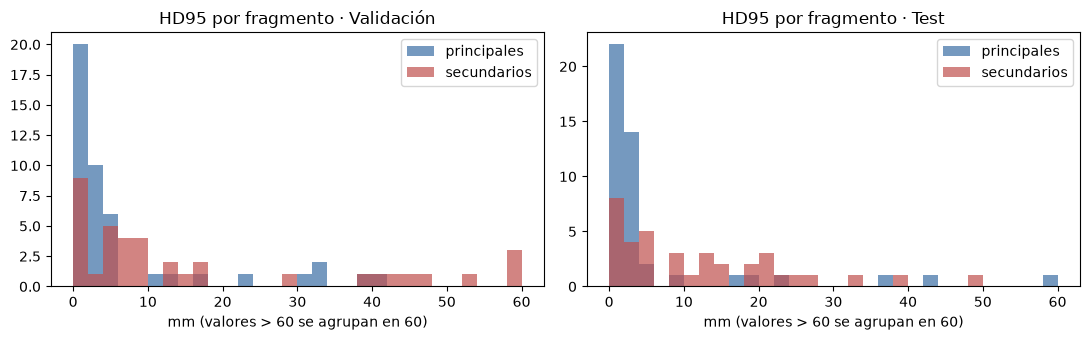

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for eje, (titulo, ruta) in zip(ejes, (("Validación", "outputs/h8/validacion/superficie_val_h8.json"),
                                       ("Test", "outputs/h8/test/superficie_test_h8.json"))):
    frags = [f for c in leer(ruta)["casos"] for f in c["fragmentos"] if f["detectado"]]
    for principal, color, nombre in ((True, "#3b6ea5", "principales"), (False, "#c0504d", "secundarios")):
        valores = [f["hd95_mm"] for f in frags if f["principal"] == principal]
        eje.hist(np.clip(valores, 0, 60), bins=np.arange(0, 62, 2), alpha=0.7, color=color, label=nombre)
    eje.set(title=f"HD95 por fragmento · {titulo}", xlabel="mm (valores > 60 se agrupan en 60)")
    eje.legend()
fig.tight_layout(); fig.savefig(FIG / "hd95_por_fragmento.png", dpi=120); plt.show()

**Lectura.** Los 90 fragmentos principales de las dos particiones se detectan, con una mediana de
unos 2 mm de HD95 y 0.5 mm de ASSD. Los secundarios son el punto débil: mediana de HD95 cercana a
8 mm y uno de cada diez sin detectar. La media es mucho mayor que la mediana porque unos pocos
fragmentos llevan un trozo aislado lejos del hueso que el HD95 castiga; la mediana describe mejor el
caso típico.

## 6. Distancia de separación en milímetros

Distancia mínima borde a borde entre cada fragmento secundario y el principal de su hueso, con
`distance_transform_edt` y el espaciado de la cabecera, medida en la predicción y en el ground truth
(`src/infer_volume.py --distance-nofill`).

In [14]:
filas = []
for particion, ruta in (("Validación", "outputs/h8/validacion/distancias_val_h8.json"),
                        ("Test", "outputs/h8/test/distancias_test_h8.json")):
    if not (ROOT / ruta).exists():
        print(f"Falta {ruta}")
        continue
    r = leer(ruta)["resumen"]
    filas.append({"Partición": particion, "Secundarios": r["n_fragmentos_secundarios"],
                  "Con distancia predicha": r["n_con_distancia_predicha"],
                  "Error medio (mm)": r.get("error_distancia_mm_media"),
                  "Error mediano (mm)": r.get("error_distancia_mm_mediana"),
                  "Error p90 (mm)": r.get("error_distancia_mm_p90"),
                  "Correlación real-predicha": r.get("correlacion_distancia")})
pd.DataFrame(filas).set_index("Partición") if filas else None

,Secundarios,Con distancia predicha,Error medio (mm),Error mediano (mm),Error p90 (mm),Correlación real-predicha
Partición,,,,,,
Validación,41,38,0.312,0.0,0.000,0.956
Test,41,37,1.516,0.0,2.557,0.811


In [15]:
separados = []
for particion, ruta in (("Validación", "outputs/h8/validacion/distancias_val_h8.json"),
                        ("Test", "outputs/h8/test/distancias_test_h8.json")):
    if (ROOT / ruta).exists():
        for c in leer(ruta)["casos"]:
            for d in c["distancias"]:
                if d["ground_truth_mm"] > 0 or (d["predicted_mm"] or 0) > 0:
                    separados.append({"Partición": particion, "Caso": c["case_id"], "Región": d["region"],
                                      "Fragmento": d["gt_id"], "Real (mm)": d["ground_truth_mm"],
                                      "Predicha (mm)": d["predicted_mm"], "Error (mm)": d["absolute_error_mm"]})
print("Fragmentos separados del principal en el ground truth o en la predicción")
pd.DataFrame(separados)

Fragmentos separados del principal en el ground truth o en la predicción


,Partición,Caso,Región,Fragmento,Real (mm),Predicha (mm),Error (mm)
0,Validación,014,coxal_derecho,24,3.493,NaN,NaN
1,Validación,024,coxal_izquierdo,13,19.043,19.043,0.000
2,Validación,024,coxal_izquierdo,14,3.175,3.938,0.762
3,Validación,087,coxal_izquierdo,14,5.291,0.000,5.291
4,Validación,099,coxal_izquierdo,12,12.817,18.630,5.813
5,Test,007,coxal_derecho,23,9.408,45.479,36.071
6,Test,039,coxal_derecho,23,33.713,NaN,NaN
7,Test,054,coxal_izquierdo,12,0.000,5.000,5.000
8,Test,054,coxal_derecho,22,0.000,1.112,1.112
9,Test,054,coxal_derecho,23,12.323,NaN,NaN


## 7. Comparación con SAM zero-shot

SAM ViT-B recibe como indicación la caja que predice H8 y devuelve una máscara binaria por región;
se compara con la máscara semántica de H8 dentro de la misma caja, en uno de cada tres cortes con
hueso. SAM es solo una línea base: no entra al pipeline ni genera etiquetas.

In [16]:
filas = []
for particion, ruta in (("Validación", "outputs/h8/validacion/sam_baseline_val_h8.json"),
                        ("Test", "outputs/h8/test/sam_baseline_test_h8.json")):
    d = leer(ruta)
    for region, v in list(d["regiones"].items()) + [("global", {"sam": d["global_sam"], "nuestro": d["global_nuestro"]})]:
        filas.append({"Partición": particion, "Región": region.replace("_", " "), "Pares": v["sam"]["n"],
                      "Dice SAM": v["sam"]["dice"], "Dice H8": v["nuestro"]["dice"],
                      "IoU SAM": v["sam"]["iou"], "IoU H8": v["nuestro"]["iou"],
                      "Diferencia de Dice": v["nuestro"]["dice"] - v["sam"]["dice"]})
    print(f"{particion}: {d['cortes']} cortes · SAM {d['ms_sam_por_corte']:.0f} ms por corte en GPU T4")
pd.DataFrame(filas).set_index(["Partición", "Región"])

Validación: 1308 cortes · SAM 450 ms por corte en GPU T4
Test: 1181 cortes · SAM 476 ms por corte en GPU T4


Pares  Dice SAM  Dice H8  IoU SAM  IoU H8  \
Partición  Región                                                       
Validación sacro              878     0.781    0.872    0.676   0.804   
           coxal izquierdo   1252     0.888    0.931    0.823   0.883   
           coxal derecho     1263     0.902    0.939    0.839   0.892   
           global            3393     0.866    0.919    0.791   0.866   
Test       sacro              766     0.794    0.886    0.690   0.824   
           coxal izquierdo   1130     0.914    0.943    0.860   0.901   
           coxal derecho     1106     0.930    0.952    0.880   0.913   
           global            3002     0.889    0.931    0.824   0.886   

                            Diferencia de Dice  
Partición  Región                               
Validación sacro                         0.091  
           coxal izquierdo               0.043  
           coxal derecho                 0.037  
           global                        0.053  
Test       sacro                         0.092  
           coxal izquierdo               0.028  
           coxal derecho                 0.021  
           global                        0.042

**Lectura.** H8 supera a SAM en las tres regiones y en las dos particiones; la mayor diferencia está
en el sacro, donde la caja es grande y el hueso esponjoso confunde a SAM. La comparación favorece a
SAM en localización, porque recibe las cajas del detector propio, y es por región completa porque
SAM no separa ni clasifica fragmentos.

## 8. Grosor de corte y umbrales del post-proceso en mm³

El modelo es 2D: acepta cualquier número de cortes y cualquier tamaño de corte (cada uno se lleva a
384 × 384). Lo que depende de la dimensión es el post-proceso 3D, que contaba sus tamaños mínimos en
vóxeles. La prueba conserva 1 de cada k cortes (`--zstep k`, solo validación) y compara los umbrales
en vóxeles con los umbrales en mm³ (`--umbral-mm`).

In [17]:
grosor = pd.read_csv(ROOT / "outputs/h8/validacion/grosor_corte/tabla_grosor_corte.csv")
grosor.set_index(["cortes_conservados", "umbrales"])

grosor_aprox_mm  secundarios_con_distancia  \
cortes_conservados umbrales                                               
1 de 1             vóxeles               0.8                         38   
                   mm³                   0.8                         38   
1 de 2             vóxeles               1.6                         38   
                   mm³                   1.6                         38   
1 de 3             vóxeles               2.4                         38   
                   mm³                   2.4                         38   

                             error_distancia_medio_mm  correlacion_distancia  \
cortes_conservados umbrales                                                    
1 de 1             vóxeles                      0.312                  0.956   
                   mm³                          0.312                  0.956   
1 de 2             vóxeles                      0.328                  0.945   
                   mm³                          0.328                  0.945   
1 de 3             vóxeles                      0.319                  0.945   
                   mm³                          0.319                  0.945   

                             dice3d_principal  dice3d_secundario  \
cortes_conservados umbrales                                        
1 de 1             vóxeles              0.918              0.722   
                   mm³                  0.918              0.722   
1 de 2             vóxeles              0.918              0.721   
                   mm³                  0.918              0.721   
1 de 3             vóxeles              0.917              0.726   
                   mm³                  0.917              0.726   

                             secundarios_perdidos_3d  cobertura  \
cortes_conservados umbrales                                       
1 de 1             vóxeles                     0.050      0.965   
                   mm³                         0.050      0.965   
1 de 2             vóxeles                     0.050      0.965   
                   mm³                         0.050      0.965   
1 de 3             vóxeles                     0.039      0.965   
                   mm³                         0.039      0.965   

                             cobertura_iou_0.5  hd95_mediana_mm  \
cortes_conservados umbrales                                       
1 de 1             vóxeles               0.849             4.05   
                   mm³                   0.849             4.05   
1 de 2             vóxeles               0.849             4.23   
                   mm³                   0.849             4.23   
1 de 3             vóxeles               0.837             4.25   
                   mm³                   0.837             4.25   

                             assd_mediana_mm  predichos_sin_pareja  
cortes_conservados umbrales                                         
1 de 1             vóxeles              0.86                   297  
                   mm³                  0.86                   278  
1 de 2             vóxeles              0.83                   257  
                   mm³                  0.83                   278  
1 de 3             vóxeles              0.75                   238  
                   mm³                  0.75                   284

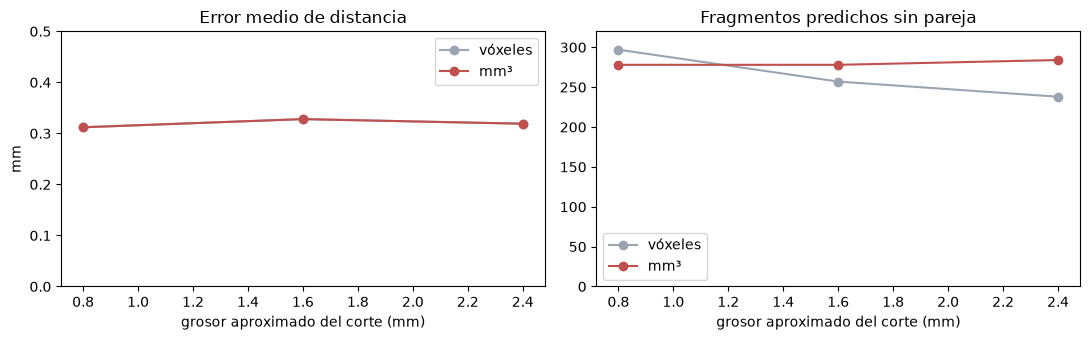

In [18]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for umbral, color in (("vóxeles", "#9aa5b1"), ("mm³", "#c0504d")):
    t = grosor[grosor["umbrales"] == umbral]
    ejes[0].plot(t["grosor_aprox_mm"], t["error_distancia_medio_mm"], "o-", color=color, label=umbral)
    ejes[1].plot(t["grosor_aprox_mm"], t["predichos_sin_pareja"], "o-", color=color, label=umbral)
ejes[0].set(title="Error medio de distancia", xlabel="grosor aproximado del corte (mm)", ylabel="mm", ylim=(0, 0.5))
ejes[1].set(title="Fragmentos predichos sin pareja", xlabel="grosor aproximado del corte (mm)", ylim=(0, 320))
ejes[0].legend(); ejes[1].legend()
fig.tight_layout(); fig.savefig(FIG / "grosor_de_corte.png", dpi=120); plt.show()

**Lectura.** Con cortes hasta tres veces más gruesos el error de distancia apenas cambia (0.31 a
0.33 mm), la cobertura sigue en 96.5 % y el Dice 3D del principal en 0.92. Los umbrales en mm³ dan
las mismas distancias y Dice que los de vóxeles, pero mantienen estable el número de fragmentos
espurios (278 a 284), mientras que en vóxeles cambia con el grosor (297, 257, 238). Por eso la demo
usa los umbrales en mm³. Se probó hasta unos 2.4 mm, no con los 3 a 5 mm habituales en clínica.

## 9. Enderezado del giro axial en la demo

La demo estima el giro del paciente dentro del escáner con la simetría de la pelvis y lo corrige si
es de 10° o más. En la validación con giro de 60°, el enderezado lleva el Dice por fragmento de
0.612 a 0.849 (sección 3).

In [19]:
filas = []
for caso in ("024", "044", "099", "039"):
    meta = leer(f"outputs/demo/h8_aumm_noise01_noema_w32_e60_s42/{caso}/meta.json")
    g, u = meta["enderezado"], meta["umbrales_postproceso"]
    filas.append({"Caso": caso, "Giro estimado (°)": g["angulo"], "Corregido": "sí" if g["corregido"] else "no",
                  "Umbral fragmento (vóxeles)": u["min_voxels"], "Umbral región (vóxeles)": u["min_region_voxels"]})
pd.DataFrame(filas).set_index("Caso")

,Giro estimado (°),Corregido,Umbral fragmento (vóxeles),Umbral región (vóxeles)
Caso,,,,
024,-1.50,no,31,201
044,0.50,no,120,795
099,-0.50,no,58,387
039,4.75,no,66,435


## 10. Conclusiones

1. H8 cumple los nueve objetivos del curso en validación y en test (Dice por fragmento de 0.865 y
   0.874).
2. Responde a las dos observaciones del profesor: no usa EMA y el giro del aumento es físico, en
   milímetros, a partir de los metadatos.
3. Es el más robusto de los cinco modelos comparados frente a ruido gaussiano, aunque con ruido
   fuerte y con giros grandes queda por debajo del objetivo.
4. CBAM aporta en detección y clasificación, no en segmentación.
5. Los fragmentos principales se segmentan y localizan bien; el punto débil siguen siendo los
   secundarios.
6. Supera a SAM zero-shot en las tres regiones (Dice global 0.931 contra 0.889 en test).
7. Tolera cortes hasta tres veces más gruesos sin cambiar las distancias; con umbrales en mm³ el
   post-proceso se comporta igual en cualquier grosor.

**Limitaciones.** Una sola semilla; ruido sintético y medido solo en validación; un giro grande
necesita el enderezado previo, que no forma parte de la inferencia por defecto; los casos 012 y 039
de test se usaron para diagnosticar fallos antes de H6, así que la cifra de test no es una
estimación independiente. El detalle está en `docs/modelo_h8.md`.